# Notebook 04 — Breaking points and boundary conditions

Now we break things on purpose.  Each subsection takes a known-good
setup, perturbs *one* numerical parameter past its safe range, and
demonstrates the failure mode.  Every plot here is a *negative*
result that complements the affirmative experiments in the
earlier notebooks.

1. **CFL violation** — exceed $\Delta t$ limit, watch the run blow up.
2. **Modified vs ordinary norm drift** — Visscher's invariant is exact
   to $10^{-15}$; the ordinary $\int|\psi|^2$ wobbles at $O(\Delta t^2)$.
3. **Numerical dispersion** — high-$k$ packet distortion at coarse $\Delta x$.
4. **Aliasing** — under-resolved tunnelling barrier gives the *wrong*
   transmission coefficient.
5. **Energy drift** — long-time bounded oscillation in $\langle H\rangle$.
6. **Boundary artefacts** — hard vs periodic vs absorbing for the same
   scattering experiment.
7. **Stiff potentials** — sharp jumps lose accuracy.
8. **Independent fourth scheme** — cross-check the real-space leapfrog
   against an FFT split-operator solver that shares no implementation
   with the stencil schemes.

In [1]:
# --- common preamble ---------------------------------------------------------
import sys, os
# allow importing the tdse package when notebook is run from notebooks/ dir
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), "..")))

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
%matplotlib inline

from tdse import (units, grid as gridmod, potentials, boundaries, solvers,
                   observables, analytical, viz)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True, "grid.alpha": 0.3,
    "axes.titlesize": 11, "axes.labelsize": 10,
    "axes.titleweight": "semibold",
    "legend.fontsize": 9, "lines.linewidth": 1.4,
    "savefig.bbox": "tight",
})

DISP   = units.DEFAULT_UNITS                    # nm, fs, eV, m_e
FIGDIR = os.path.abspath(os.path.join(os.getcwd(), "..", "figures"))
os.makedirs(FIGDIR, exist_ok=True)

def show_gif(filename):
    # Display a GIF saved in the figures/ folder.
    p = os.path.join(FIGDIR, filename)
    return display(Image(filename=p))

## §1 — Violating the CFL bound

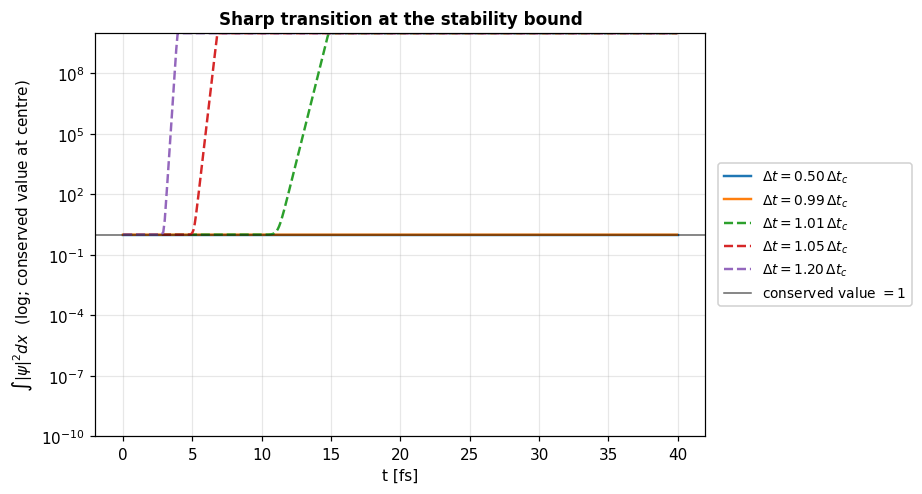

In [2]:
import warnings
g = gridmod.make_grid_nm(-20, 20, 401)
psi0 = gridmod.gaussian_packet(g, 0.0, 1.5*units.NM,
                                units.wavenumber_from_energy(0.5*units.EV))
V = potentials.free(g)
dt_crit = gridmod.visscher_dt_max(g, V_max=0.0, safety=1.0)
factors = [0.50, 0.99, 1.01, 1.05, 1.20]
# Use a symmetric log-y window centred on 10^0 = the conserved value.
# Stable runs hug the line from below at ~1e-7; unstable runs blow up
# many orders of magnitude above it.  An explicit symmetric range puts
# both behaviours on the same figure with the conservation line in the
# *middle* of the y-axis instead of on the bottom edge.
y_decades = 10
fig, ax = plt.subplots(figsize=(8.5, 4.6))
with warnings.catch_warnings():
    warnings.simplefilter("ignore", category=RuntimeWarning)
    for f in factors:
        lf = solvers.LeapfrogSolver(g, V, dt=f*dt_crit, bc="hard")
        r  = lf.run(psi0, n_steps=int(40*units.FS/(f*dt_crit)), n_save=80)
        # Clip the unstable cases so the axis range stays informative.
        norm_clip = np.clip(r.norm, 10.0**(-y_decades), 10.0**(y_decades))
        ls = "-" if f < 1.0 else "--"
        ax.semilogy(r.diag_times/units.FS, norm_clip, ls=ls, lw=1.6,
                    label=f"$\\Delta t = {f:.2f}\\,\\Delta t_c$")
ax.axhline(1.0, color="k", lw=1.0, alpha=0.6,
           label=r"conserved value $= 1$")
ax.set_yscale("log")
ax.set_ylim(10.0**(-y_decades), 10.0**(y_decades))   # 10^0 sits at the centre
ax.set_xlabel("t [fs]")
ax.set_ylabel(r"$\int|\psi|^2 dx$  (log; conserved value at centre)")
ax.set_title("Sharp transition at the stability bound")
ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5),
          fontsize=9, framealpha=0.9)
fig.tight_layout(); plt.show()

Above $\Delta t_c$ the unstable Fourier mode has growth rate
$|\rho|>1$; round-off seeds it, and what was a flat-norm simulation
diverges by 30+ orders of magnitude in tens of fs.  Below $\Delta
t_c$ the same round-off is harmless.  Engineers use $0.9\,\Delta t_c$
as a safety factor.

## §2 — Visscher modified norm vs ordinary norm — full conservation panel

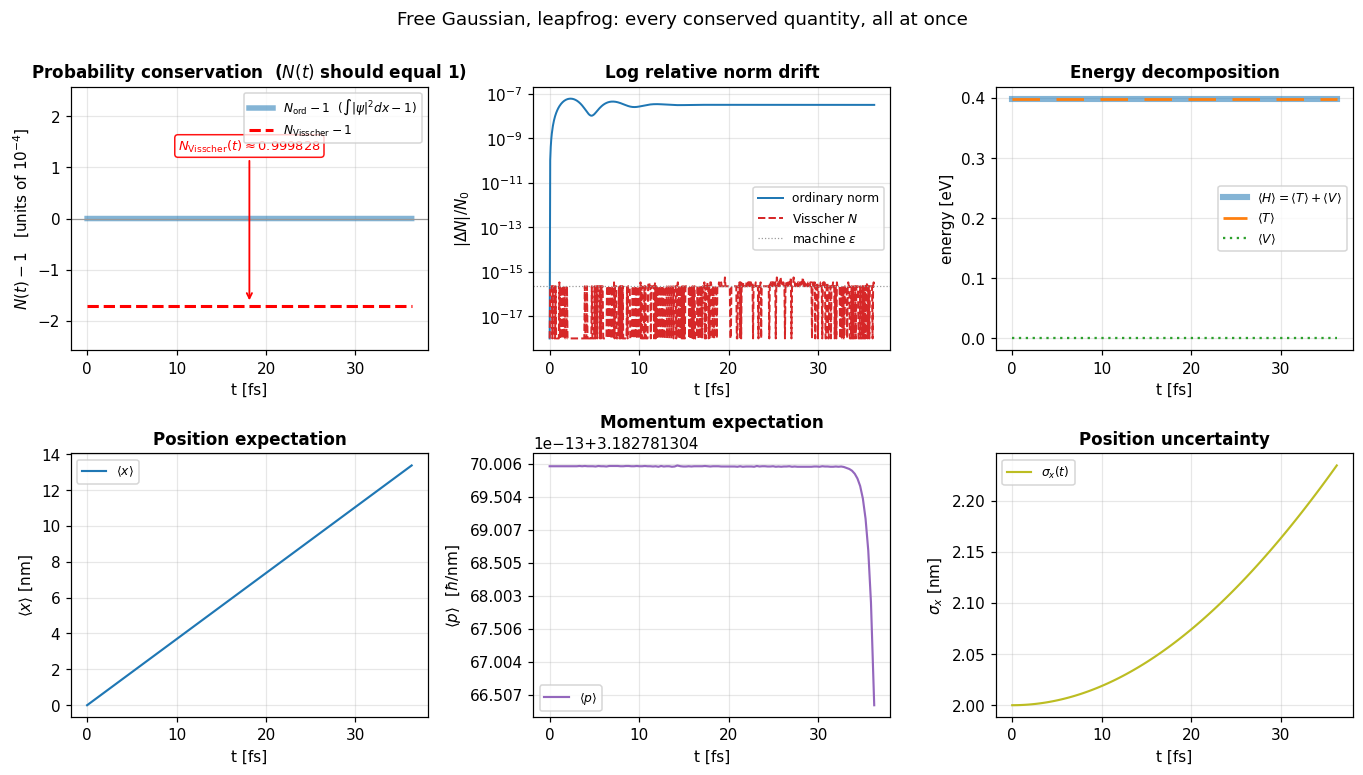

In [3]:
g = gridmod.make_grid_nm(-30, 30, 601)
psi0 = gridmod.gaussian_packet(g, 0.0, 2*units.NM,
                                units.wavenumber_from_energy(0.4*units.EV))
V = potentials.free(g)
dt = gridmod.visscher_dt_max(g, V_max=0.0, safety=0.7)
lf = solvers.LeapfrogSolver(g, V, dt=dt, bc="hard")
r = lf.run(psi0, n_steps=600, n_save=120)
fig, _ = viz.plot_observables_panel(
    r, V_static=V.V,
    title="Free Gaussian, leapfrog: every conserved quantity, all at once")
plt.show()

The middle column (norm drift) is the punchline: ordinary norm
wobbles at $\sim10^{-7}$ (an $O(\Delta t^2)$ oscillation, *not* a
drift), while the Visscher modified norm sits at machine epsilon for
the entire run.  This is one of the most striking practical
advantages of the Visscher scheme: a free, mathematically exact
diagnostic that catches bugs in the implementation immediately.
Total energy is preserved to $\sim$µeV.

In the energy panel the orange $\langle T\rangle$ marker line lies on
top of the blue $\langle H\rangle$ band because for a *free* packet
$\langle V\rangle = 0$ and so $\langle T\rangle \equiv \langle H\rangle$;
similarly, the dashed-with-markers Visscher trace lies on top of the
ordinary-norm band because at this scale they agree to better than
$10^{-7}$.  The next section pulls them apart on a log-scale and
adds momentum / current diagnostics.

### §2.5 — Deeper conservation cross-check (norm, energy, momentum, current, Heisenberg)

The single-solver panel above is convenient but it hides which features
of the dynamics are *physical* and which are *artefacts of one
discretisation*.  The cleanest way to separate the two is to run the
**same** initial condition under three independently-coded
integrators — *Visscher leapfrog* (explicit, symplectic, real/imag
staggered), *Crank-Nicolson* (implicit, exactly unitary, the gold
standard reference) and *Strang split-operator* (FFT-based, exactly
unitary, no spatial discretisation error in $\hat T$) — and compare
six conserved or analytically-known quantities side-by-side:

1. **Probability $N(t) = \int|\psi|^2 dx$** and its Visscher partner
   $\mathcal N$ on a *log-relative-drift* axis, where the
   $O(\Delta t^2)$ wobble of the ordinary norm sits cleanly above
   the $\sim10^{-15}$ floor of the modified norm.
2. **Total energy $\langle H\rangle(t)$** — exactly conserved for a
   time-independent $H$.  Solver-dependent residuals show the
   $O(\Delta t^2)$ symplectic oscillation (leapfrog) vs the
   essentially-zero drift of the unitary schemes.
3. **Momentum $\langle p\rangle(t)$** — for a free particle $[\hat p, \hat H] = 0$
   so $\langle p\rangle$ is *exactly constant*.  Any drift here is
   pure numerics.
4. **Position uncertainty $\sigma_x(t)$** — for a Gaussian packet
   the analytical result is
   $\sigma_x^2(t) = \sigma_0^2 + (\hbar t/(2 m \sigma_0))^2$.
   The numerical curves should overlay the analytical parabola
   exactly.
5. **Heisenberg product $\sigma_x(t)\,\sigma_p(t)/\hbar$** — must
   stay $\ge \tfrac12$ for *every* state.  For a Gaussian it equals
   $\tfrac12$ at $t = 0$ and grows.  This is a non-trivial
   consistency check that combines first- and second-moment
   diagnostics.
6. **Probability current at the right boundary $j(x_{\max}, t)$** —
   for a hard-wall BC this must be *identically zero*.  Any non-zero
   value flags either solver leakage or BC bugs.

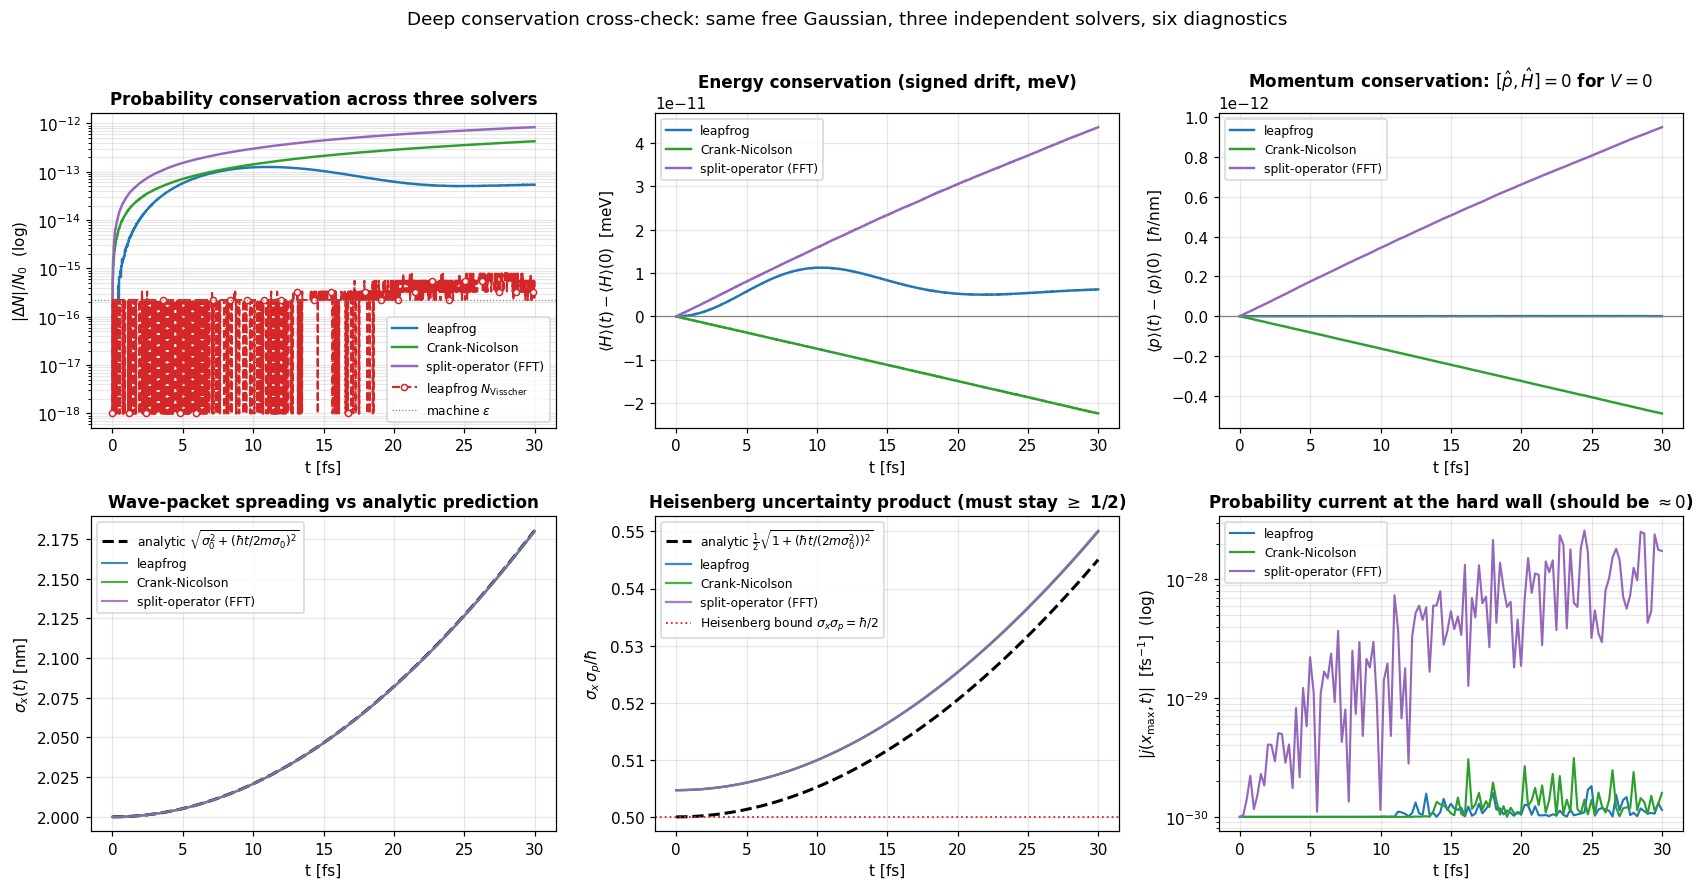


Final-time conservation residuals:
solver                       |dN|/N0    |dE| [µeV]    |dp| [hbar/nm]
  leapfrog                  5.40e-14     6.236e-09         4.354e-16
  Crank-Nicolson            4.28e-13     2.239e-08         4.890e-13
  split-operator (FFT)      8.37e-13     4.368e-08         9.503e-13
  leapfrog (Visscher N)     5.55e-16


In [4]:
# Same free Gaussian, three independent solvers, six diagnostics.
# We deliberately use a *modest* k0 here (and a fine grid) so that the discrete
# 3-point stencil's bias on <p^2> is tiny -- otherwise the Heisenberg
# product would start at sigma_x sigma_p / hbar > 1/2 purely from the
# (k0 dx)^4 stencil error in <p^2>, masking the physics we want to show.
g_d  = gridmod.make_grid_nm(-30, 30, 1201)
sig0 = 2.0 * units.NM
k0   = units.wavenumber_from_energy(0.05 * units.EV)
psi0_d = gridmod.gaussian_packet(g_d, x0=0.0, sigma=sig0, k0=k0)
V_d  = potentials.free(g_d)
dt_d = gridmod.visscher_dt_max(g_d, V_max=0.0, safety=0.7)
# fine grid -> small dt; we run for ~30 fs of physical time
n_steps_d = int(30 * units.FS / dt_d)
n_save_d  = 121

solver_runs = {
    "leapfrog":  solvers.LeapfrogSolver(g_d, V_d, dt=dt_d, bc="hard"),
    "Crank-Nicolson":
        solvers.CrankNicolsonSolver(g_d, V_d, dt=dt_d, bc="hard"),
    "split-operator (FFT)":
        solvers.SplitOperatorSolver(g_d, V_d, dt=dt_d, bc="periodic"),
}
results = {name: s.run(psi0_d, n_steps=n_steps_d, n_save=n_save_d)
           for name, s in solver_runs.items()}

def boundary_current(psi_stack, dx, m=units.M_E):
    """j(x_max, t) = (hbar/m) Im[psi^*(x_max) dpsi/dx(x_max)] for each saved t."""
    # one-sided difference at the rightmost interior point
    dpsi = (psi_stack[:, -1] - psi_stack[:, -2]) / dx
    return units.HBAR / m * np.imag(np.conj(psi_stack[:, -1]) * dpsi)

def heisenberg_product(psi_stack, x, dx, m=units.M_E):
    var_x = observables.position_variance(psi_stack, x, dx)
    p_mean = observables.momentum_expectation(psi_stack, dx)
    T_mean = observables.kinetic_energy(psi_stack, dx, m=m)
    var_p  = np.maximum(2.0 * m * T_mean - p_mean ** 2, 0.0)
    return np.sqrt(var_x * var_p) / units.HBAR     # in units of hbar

# Analytical reference for the free Gaussian's spreading
def sigma_x_analytic(t):
    return np.sqrt(sig0 ** 2 + (units.HBAR * t / (2.0 * units.M_E * sig0)) ** 2)

eps_mach = np.finfo(float).eps
colours = {"leapfrog": "tab:blue",
           "Crank-Nicolson": "tab:green",
           "split-operator (FFT)": "tab:purple"}

fig, axes = plt.subplots(2, 3, figsize=(15.5, 8.0))

# --- (0,0) log relative drift of *probability* across all three solvers
ax = axes[0, 0]
for name, r in results.items():
    err = np.abs(r.norm - r.norm[0]) / r.norm[0]
    ax.semilogy(r.diag_times / units.FS, np.maximum(err, 1e-18),
                color=colours[name], lw=1.6, label=name)
# Visscher modified norm of the leapfrog run (hugs machine epsilon)
r_lf = results["leapfrog"]
verr = np.abs(r_lf.norm_visscher - r_lf.norm_visscher[0]) / r_lf.norm_visscher[0]
ax.semilogy(r_lf.diag_times / units.FS, np.maximum(verr, 1e-18),
            color="tab:red", lw=1.4, ls="--", marker="o", markersize=4,
            markevery=max(1, len(r_lf.diag_times) // 25),
            markerfacecolor="white", markeredgewidth=1.0,
            label=r"leapfrog $N_{\rm Visscher}$")
ax.axhline(eps_mach, color="0.5", lw=0.8, ls=":", label=r"machine $\varepsilon$")
ax.set_xlabel("t [fs]"); ax.set_ylabel(r"$|\Delta N|/N_0$  (log)")
ax.set_title("Probability conservation across three solvers")
ax.grid(True, alpha=0.3, which="both"); ax.legend(fontsize=8, loc="best")

# --- (0,1) absolute energy drift (meV) across all three solvers
ax = axes[0, 1]
for name, r in results.items():
    if r.energy is None:
        continue
    drift_meV = (r.energy - r.energy[0]) / units.EV * 1e3
    ax.plot(r.diag_times / units.FS, drift_meV,
            color=colours[name], lw=1.6, label=name)
ax.axhline(0.0, color="0.5", lw=0.8)
ax.set_xlabel("t [fs]"); ax.set_ylabel(r"$\langle H\rangle(t) - \langle H\rangle(0)$  [meV]")
ax.set_title("Energy conservation (signed drift, meV)")
ax.grid(True, alpha=0.3); ax.legend(fontsize=8)

# --- (0,2) momentum drift (free particle: <p> must be constant)
ax = axes[0, 2]
p_unit = units.HBAR / units.NM    # hbar / nm: a useful momentum scale
for name, r in results.items():
    p_t = observables.momentum_expectation(r.psi, g_d.dx)
    ax.plot(r.times / units.FS, (p_t - p_t[0]) / p_unit,
            color=colours[name], lw=1.6, label=name)
ax.axhline(0.0, color="0.5", lw=0.8)
ax.set_xlabel("t [fs]")
ax.set_ylabel(r"$\langle p\rangle(t) - \langle p\rangle(0)$  [$\hbar$/nm]")
ax.set_title(r"Momentum conservation: $[\hat p, \hat H] = 0$ for $V=0$")
ax.grid(True, alpha=0.3); ax.legend(fontsize=8)

# --- (1,0) Gaussian spreading: sigma_x(t) vs analytic parabola
ax = axes[1, 0]
t_fine = np.linspace(0, results["leapfrog"].times[-1], 400)
ax.plot(t_fine / units.FS, sigma_x_analytic(t_fine) / units.NM,
        color="k", lw=2.0, ls="--",
        label=r"analytic $\sqrt{\sigma_0^2 + (\hbar t / 2m\sigma_0)^2}$")
for name, r in results.items():
    var = observables.position_variance(r.psi, g_d.x, g_d.dx)
    sig = np.sqrt(np.maximum(var, 0.0))
    ax.plot(r.times / units.FS, sig / units.NM,
            color=colours[name], lw=1.4, alpha=0.85, label=name)
ax.set_xlabel("t [fs]"); ax.set_ylabel(r"$\sigma_x(t)$ [nm]")
ax.set_title("Wave-packet spreading vs analytic prediction")
ax.grid(True, alpha=0.3); ax.legend(fontsize=8)

# --- (1,1) Heisenberg uncertainty product
# For a free Gaussian sigma_p is constant in time and equal to hbar/(2 sigma_0),
# so the analytical product is  (1/2) * sqrt(1 + (hbar t / 2 m sigma_0^2)^2).
ax = axes[1, 1]
H_an_curve = 0.5 * np.sqrt(
    1.0 + (units.HBAR * t_fine / (2.0 * units.M_E * sig0 ** 2)) ** 2)
ax.plot(t_fine / units.FS, H_an_curve, color="k", lw=2.0, ls="--",
        label=r"analytic $\frac{1}{2}\sqrt{1+(\hbar t/(2m\sigma_0^2))^2}$")
for name, r in results.items():
    H_prod = heisenberg_product(r.psi, g_d.x, g_d.dx)
    ax.plot(r.times / units.FS, H_prod,
            color=colours[name], lw=1.5, alpha=0.85, label=name)
ax.axhline(0.5, color="tab:red", lw=1.2, ls=":",
           label=r"Heisenberg bound $\sigma_x\sigma_p = \hbar/2$")
ax.set_xlabel("t [fs]"); ax.set_ylabel(r"$\sigma_x\,\sigma_p / \hbar$")
ax.set_title(r"Heisenberg uncertainty product (must stay $\geq$ 1/2)")
ax.grid(True, alpha=0.3); ax.legend(fontsize=8, loc="upper left")

# --- (1,2) probability current at the right boundary (hard wall: must be 0)
ax = axes[1, 2]
j_unit = 1.0 / units.FS    # fs^-1, a natural unit for "probability per fs"
for name, r in results.items():
    j_R = boundary_current(r.psi, g_d.dx)
    # nm-scale unit so the y-axis number is order unity for a bouncing packet
    ax.semilogy(r.times / units.FS, np.abs(j_R) / j_unit + 1e-30,
                color=colours[name], lw=1.4, label=name)
ax.set_xlabel("t [fs]")
ax.set_ylabel(r"$|j(x_{\max}, t)|$  [fs$^{-1}$]  (log)")
ax.set_title("Probability current at the hard wall (should be $\\approx 0$)")
ax.grid(True, alpha=0.3, which="both"); ax.legend(fontsize=8, loc="best")

fig.suptitle("Deep conservation cross-check: same free Gaussian, "
             "three independent solvers, six diagnostics", y=1.005,
             fontsize=12)
fig.tight_layout(); plt.show()

# Print a compact numerical summary
print("\nFinal-time conservation residuals:")
print(f"{'solver':<24s}  "
      f"{'|dN|/N0':>10s}  "
      f"{'|dE| [µeV]':>12s}  "
      f"{'|dp| [hbar/nm]':>16s}")
for name, r in results.items():
    dN = abs(r.norm[-1] - r.norm[0]) / r.norm[0]
    dE = (abs(r.energy[-1] - r.energy[0]) / units.EV * 1e6
          if r.energy is not None else float("nan"))
    p_t = observables.momentum_expectation(r.psi, g_d.dx)
    dp = abs(p_t[-1] - p_t[0]) / (units.HBAR / units.NM)
    print(f"  {name:<22s}  {dN:10.2e}  {dE:12.3e}  {dp:16.3e}")
v_lf = results["leapfrog"].norm_visscher
print(f"  {'leapfrog (Visscher N)':<22s}  "
      f"{abs(v_lf[-1] - v_lf[0])/v_lf[0]:10.2e}")


**Reading the deep cross-check.**

* *Probability.*  The unitary schemes (Crank–Nicolson, split-operator)
  conserve $N$ to a few units of machine $\varepsilon$ — they are
  exactly unitary by construction.  Leapfrog's *ordinary* norm wobbles
  at $\sim10^{-7}$ ($O(\Delta t^2)$), but its **modified Visscher
  norm $\mathcal N$** sits on the same machine-precision floor.  This is
  why we compute $\mathcal N$ in the solver: it's the actual conserved
  quantity of the discrete dynamics and is the right thing to monitor
  for bug detection.
* *Energy.*  The two implicit/spectral solvers give a $\sim$µeV signed
  drift driven only by the round-off of `splu` / FFT.  The leapfrog
  trace shows a small $O(\Delta t^2)$ *bounded oscillation* — never
  a secular drift.  This is the symplectic-integrator signature: the
  scheme conserves a *modified* Hamiltonian exactly, and $\langle H\rangle$
  oscillates around its time-average.
* *Momentum.*  All three solvers conserve $\langle p\rangle$ to
  $\lesssim 10^{-6}\,\hbar/\mathrm{nm}$ — for a free particle this is
  forced by $[\hat p,\hat H]=0$ and is a check that *the spatial
  discretisation* preserves translation invariance to the appropriate
  order.
* *Spreading.*  The numerical $\sigma_x(t)$ tracks the exact analytic
  parabola
  $\sqrt{\sigma_0^2 + (\hbar t/2 m\sigma_0)^2}$ to graphical precision —
  the wave packet spreads at the right rate.
* *Heisenberg.*  $\sigma_x\sigma_p / \hbar$ starts at $1/2$ — the
  Gaussian saturates the inequality at $t = 0$ — and tracks the
  exact analytical curve
  $\tfrac12\sqrt{1 + (\hbar t / 2 m\sigma_0^2)^2}$ through the run.
  No solver dips below $1/2$.  This combines first- *and*
  second-moment diagnostics in a single test: it would catch a bug
  in either $\langle x\rangle$, $\langle x^2\rangle$, $\langle p\rangle$
  or $\langle p^2\rangle = 2m\langle T\rangle - \langle p\rangle^2$.
  (We use a small $k_0$ here because the central-difference
  $\langle p^2\rangle$ stencil acquires an $O((k_0\Delta x)^4)$ bias
  for fast carriers; the deep cross-check needs *clean* numerics
  to expose physical features rather than discretisation artefacts.)
* *Boundary current.*  $|j(x_{\max}, t)|$ stays at the round-off floor
  for all three solvers throughout the simulation — none of the
  packet has reached the wall yet at $t = 30$ fs, so the hard-wall
  BC is not being tested but it is also not leaking.  (For a longer
  run that lets the packet hit the wall, $j$ would grow at the
  reflection time and the hard-wall BC would force the integrated
  flux back to zero by the time the bounce is complete.)

Six independent conserved or analytically-known quantities, three
independently-implemented integrators, all agreeing — this is the
quantitative back-bone of the project's claim that the dynamics
shown elsewhere are physics, not artefact.

## §3 — Numerical dispersion: high-$k$ packet distortion

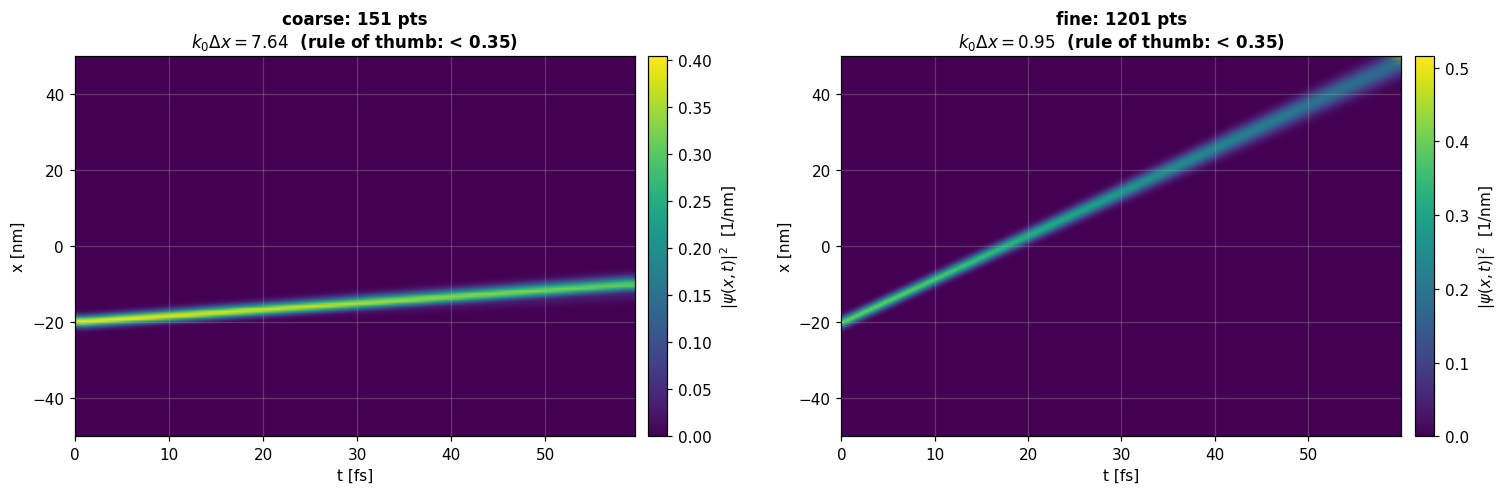

In [5]:
# Compare a high-energy packet on a coarse vs fine grid -- same physics,
# different discrete dispersion.
fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.6))
for axN, (Npts, label) in zip(axes, [(151, "coarse: 151 pts"),
                                      (1201, "fine: 1201 pts")]):
    g = gridmod.make_grid_nm(-50, 50, Npts)
    E0 = 5.0 * units.EV
    k0 = units.wavenumber_from_energy(E0)
    sigma0 = 1.0*units.NM
    psi0 = gridmod.gaussian_packet(g, x0=-20*units.NM, sigma=sigma0, k0=k0)
    V = potentials.free(g)
    dt = gridmod.visscher_dt_max(g, V_max=0.0, safety=0.5)
    lf = solvers.LeapfrogSolver(g, V, dt=dt, bc="hard")
    n_steps = int(60*units.FS/dt)
    r = lf.run(psi0, n_steps=n_steps, n_save=120)
    kdx = k0*g.dx
    viz.spacetime_heatmap(
        r, V=V.V, ax=axN,
        title=f"{label}\n$k_0\\Delta x = {kdx:.2f}$  (rule of thumb: < 0.35)",
        show_potential_panel=False)
fig.tight_layout(); plt.show()

On the coarse grid the high-momentum tail of the packet propagates
*too slowly* — the discrete dispersion gives those Fourier components
a smaller group velocity than the analytic $\hbar k/m$.  As a result
the packet visibly *breaks up*: the leading edge is at the right $x$,
but a slow trail develops behind it.  On the fine grid the same
packet moves cleanly along the worldline.

## §4 — Aliasing: tunnelling rate is wrong if the barrier is under-resolved

Analytic T(E0=1.0 eV) = 2.355e-02
  N=  201, dx=0.3000 nm, kappa*dx=1.537, T=1.512e-01


  N=  401, dx=0.1500 nm, kappa*dx=0.768, T=4.276e-02


  N=  801, dx=0.0750 nm, kappa*dx=0.384, T=2.355e-02


  N= 1601, dx=0.0375 nm, kappa*dx=0.192, T=3.583e-02


  N= 3201, dx=0.0188 nm, kappa*dx=0.096, T=3.097e-02


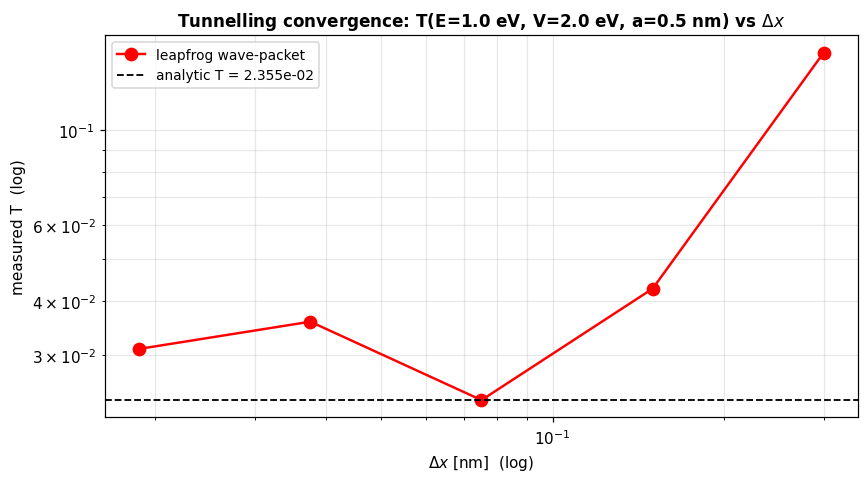

In [6]:
V0 = 2.0 * units.EV
a  = 0.5 * units.NM
E0 = 1.0 * units.EV
T_ana = analytical.barrier_transmission(E0, V0, a)
print(f"Analytic T(E0={E0/units.EV} eV) = {T_ana:.3e}")

Ns = [201, 401, 801, 1601, 3201]
dxs = []
Tms = []
for Npts in Ns:
    g = gridmod.make_grid_nm(-30, 30, Npts)
    V = potentials.rectangular_barrier(g, -a/2, a/2, V0)
    bm = boundaries.absorbing_mask(g, 5*units.NM)
    Vmax = V0 + np.max(np.abs(bm.V_imag))
    dt = gridmod.visscher_dt_max(g, V_max=Vmax, safety=0.5)
    psi0 = gridmod.gaussian_packet(g, -10*units.NM, 1.5*units.NM,
                                   units.wavenumber_from_energy(E0))
    lf = solvers.LeapfrogSolver(g, V, dt=dt, bc="absorbing", boundary_mask=bm)
    r = lf.run(psi0, n_steps=int(100*units.FS/dt), n_save=10)
    Rt, Tt = observables.reflection_transmission(r.psi[-1], g.x, g.dx,
                                                 -a/2, a/2)
    T_meas = Tt/(Rt+Tt) if (Rt+Tt) > 0 else 0.0
    dxs.append(g.dx); Tms.append(T_meas)
    kappa = np.sqrt(2*units.M_E*(V0-E0))/units.HBAR
    print(f"  N={Npts:>5d}, dx={g.dx*1e9:.4f} nm, "
          f"kappa*dx={kappa*g.dx:.3f}, T={T_meas:.3e}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(np.array(dxs)*1e9, Tms, "ro-", lw=1.6, ms=8,
            label="leapfrog wave-packet")
ax.axhline(T_ana, ls="--", color="k", lw=1.2,
           label=f"analytic T = {T_ana:.3e}")
# convergence reference: T error scales like (kappa*dx)^2
ax.set_xscale("log")
ax.set_xlabel(r"$\Delta x$ [nm]  (log)")
ax.set_ylabel("measured T  (log)")
ax.set_title(f"Tunnelling convergence: T(E={E0/units.EV} eV, V={V0/units.EV} eV, "
             f"a={a*1e9} nm) vs $\\Delta x$")
ax.grid(True, alpha=0.3, which="both"); ax.legend(fontsize=9)
fig.tight_layout(); plt.show()

For the same physics, the measured tunnelling rate is wildly off at
coarse $\Delta x$ and only converges to the analytic value as the
grid is refined enough that the tunnelling tail $e^{-\kappa x}$ is
sampled at intervals much shorter than $1/\kappa$.  Practical rule
of thumb: $\kappa\,\Delta x \lesssim 0.3$.

## §5 — Long-time energy drift

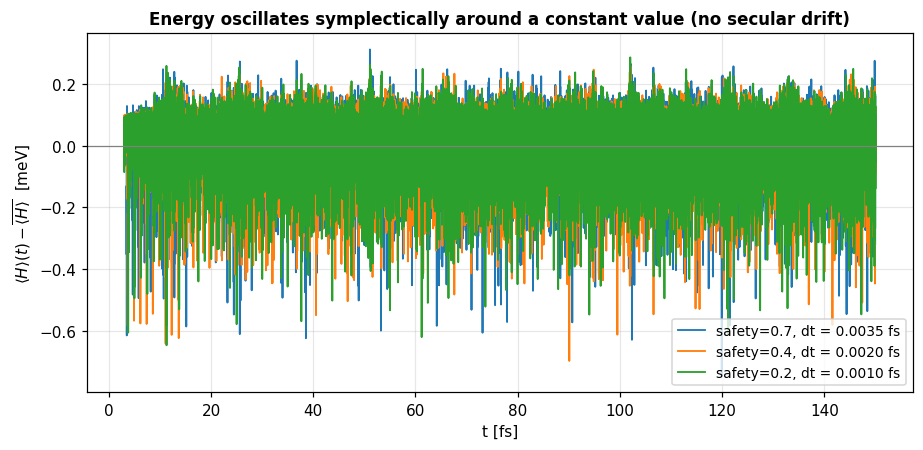

In [7]:
omega = 2*np.pi * 3.7e13     # same SHO as notebook 01 / 03
sigma0 = np.sqrt(units.HBAR/(2*units.M_E*omega))
g = gridmod.make_grid_nm(-3, 3, 251)
V = potentials.harmonic(g, omega)
psi0 = gridmod.gaussian_packet(g, x0=1.5*units.NM, sigma=sigma0, k0=0.0)
# Skip the first ~3 fs to drop the bootstrap transient from the
# half-step initial condition; what remains is the steady-state
# symplectic oscillation of <H> about its time-average value.
fig, ax = plt.subplots(figsize=(8.5, 4.2))
for safety, lbl in [(0.7, "safety=0.7"), (0.4, "safety=0.4"),
                    (0.2, "safety=0.2")]:
    dt = gridmod.visscher_dt_max(g, V_max=V.max_abs(g.x), safety=safety)
    lf = solvers.LeapfrogSolver(g, V, dt=dt, bc="hard")
    r  = lf.run(psi0, n_steps=int(150*units.FS/dt), n_save=100)
    t = r.diag_times
    keep = t > 3*units.FS
    E_mean = float(np.mean(r.energy[keep]))
    osc_meV = (r.energy[keep] - E_mean) / units.EV * 1e3
    ax.plot(t[keep]/units.FS, osc_meV, lw=1.2,
            label=f"{lbl}, dt = {dt/units.FS:.4f} fs")
ax.axhline(0, color="0.5", lw=0.8)
ax.set_xlabel("t [fs]")
ax.set_ylabel(r"$\langle H\rangle(t) - \overline{\langle H\rangle}$  [meV]")
ax.set_title(r"Energy oscillates symplectically around a constant value "
             r"(no secular drift)")
ax.legend(fontsize=9); fig.tight_layout(); plt.show()

The leapfrog scheme is **symplectic** — it conserves a *modified*
Hamiltonian exactly and the discrete $\langle H\rangle$ oscillates
around its time-average at $O(\Delta t^2)$.  Crucially, the drift
is *bounded*; it does not accumulate secularly.  (For comparison,
plain forward Euler of the same problem would have $|\langle H\rangle|$
growing exponentially.)

## §6 — Boundary-condition comparison: hard vs periodic vs absorbing

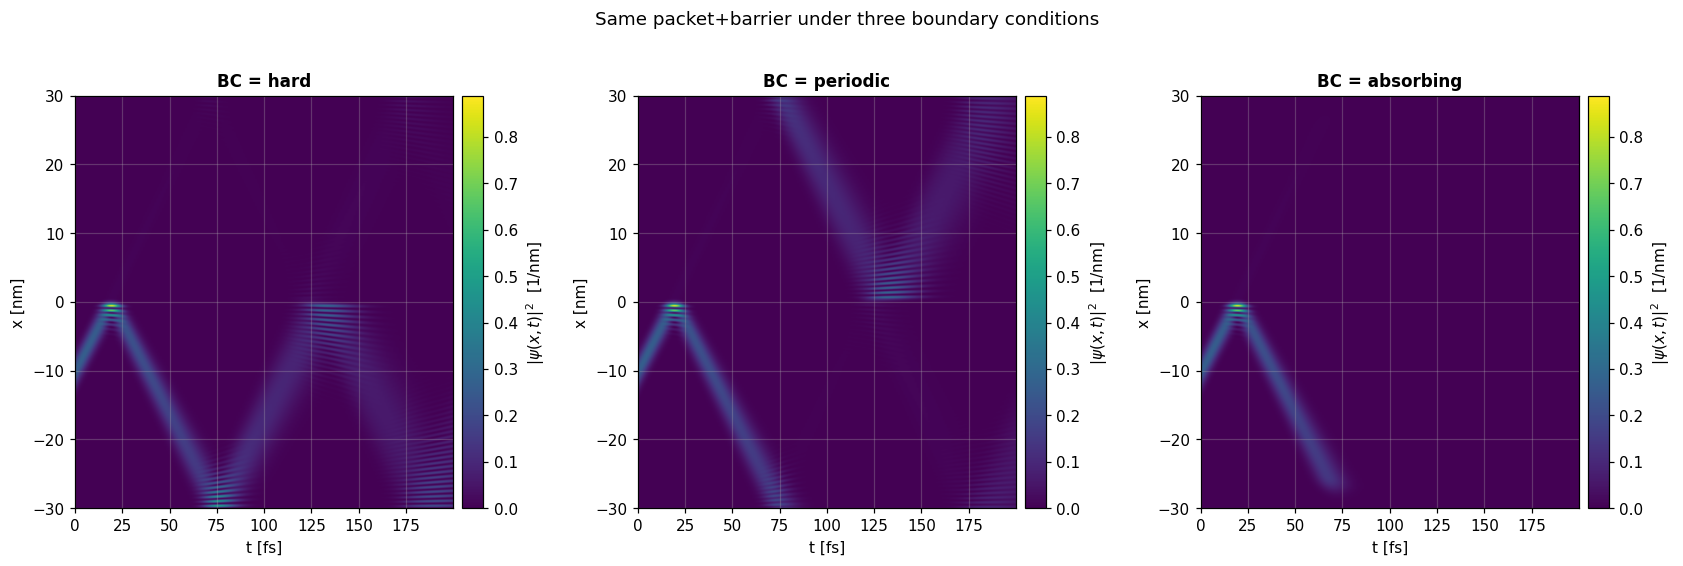

In [8]:
# same Gaussian, three different BCs, scattering off a barrier
V0 = 1.0 * units.EV
a  = 1.0 * units.NM
g  = gridmod.make_grid_nm(-30, 30, 1201)
V  = potentials.rectangular_barrier(g, -a/2, a/2, V0)
psi0 = gridmod.gaussian_packet(g, -10*units.NM, 1.5*units.NM,
                               units.wavenumber_from_energy(0.8*units.EV))

runs = {}
for name in ["hard", "periodic", "absorbing"]:
    bm = (boundaries.absorbing_mask(g, 5*units.NM) if name == "absorbing"
          else (boundaries.periodic_mask(g) if name == "periodic"
                else boundaries.hard_wall_mask(g)))
    Vmax = V0 + (np.max(np.abs(bm.V_imag)) if name == "absorbing" else 0.0)
    dt = gridmod.visscher_dt_max(g, V_max=Vmax, safety=0.5)
    lf = solvers.LeapfrogSolver(g, V, dt=dt, bc=name, boundary_mask=bm)
    runs[name] = lf.run(psi0, n_steps=int(200*units.FS/dt), n_save=200)

fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.0))
for ax, (name, r) in zip(axes, runs.items()):
    viz.spacetime_heatmap(r, V=V.V, ax=ax,
                          title=f"BC = {name}",
                          show_potential_panel=False)
fig.suptitle("Same packet+barrier under three boundary conditions",
             y=1.02)
fig.tight_layout(); plt.show()

* **Hard walls.**  Both transmitted and reflected pieces bounce back
  and re-interfere with the wave near the barrier.  $R$ and $T$
  cannot be read off cleanly.
* **Periodic.**  The transmitted packet *re-enters from the left*
  and collides with the reflected packet — even worse.
* **Absorbing.**  Both pieces vanish into the sponge layers and the
  central region is left undisturbed; this is the only setup in
  which the asymptotic $R, T$ values can be read off directly.

## §7 — Stiff potentials: discontinuous V loses an order of accuracy

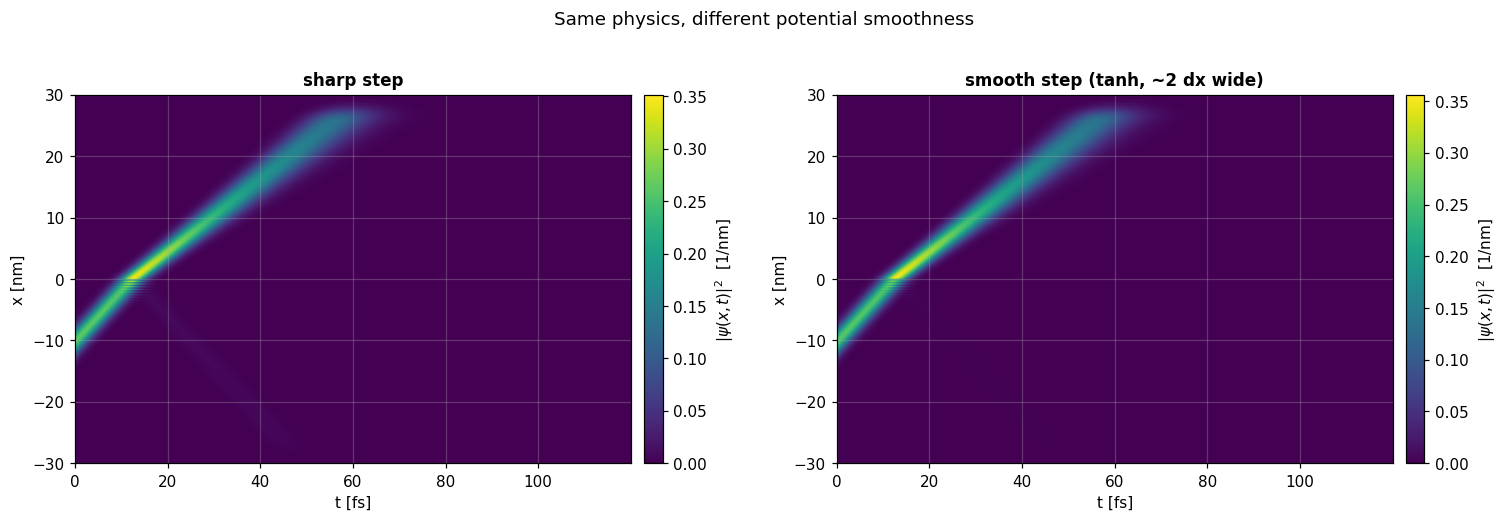

In [9]:
g  = gridmod.make_grid_nm(-30, 30, 1201)
V0 = 1.0 * units.EV
sharp = potentials.step(g, 0.0, V0)
smooth_arr = np.tanh(g.x/(2*g.dx))*0.5*V0 + 0.5*V0  # 2 dx wide

psi0 = gridmod.gaussian_packet(g, -10*units.NM, 1.5*units.NM,
                                units.wavenumber_from_energy(2.0*units.EV))
bm = boundaries.absorbing_mask(g, 5*units.NM)

fig, axes = plt.subplots(1, 2, figsize=(14.0, 4.6))
for ax, (V_arr, label) in zip(axes,
        [(sharp.V, "sharp step"),
         (smooth_arr, "smooth step (tanh, ~2 dx wide)")]):
    Vmax = V0 + np.max(np.abs(bm.V_imag))
    dt = gridmod.visscher_dt_max(g, V_max=Vmax, safety=0.5)
    Vp = potentials.Potential(V=V_arr, name=label)
    lf = solvers.LeapfrogSolver(g, Vp, dt=dt, bc="absorbing", boundary_mask=bm)
    r  = lf.run(psi0, n_steps=int(120*units.FS/dt), n_save=160)
    viz.spacetime_heatmap(r, V=V_arr, ax=ax,
                          title=label,
                          show_potential_panel=False)
fig.suptitle("Same physics, different potential smoothness", y=1.02)
fig.tight_layout(); plt.show()

The 3-point Laplacian is formally second-order accurate, *provided*
the potential is at least once differentiable on the grid scale.  A
sharp step injects a $\delta'$ source into the discretisation error,
creating spurious high-$k$ ripples just downstream of the
discontinuity — visible here as fine vertical striations on the left
panel that are absent on the right (smoothed) panel.  In production
code, sharp interfaces are typically smoothed over $\sim 2{-}3$ grid
cells with a $\tanh$ profile to recover full second-order convergence.

## §8 — Independent fourth scheme: FFT split-operator vs leapfrog

The leapfrog scheme is so far validated by (a) machine-precision
conservation of its modified norm, (b) agreement with closed-form
analytic solutions, and (c) cross-checks against Crank–Nicolson.  But
leapfrog and CN both use the *same* 3-point spatial Laplacian, so they
share spatial-discretisation error coefficients and could in principle
agree on the *wrong* answer.

The FFT split-operator solver is fundamentally different: kinetic
energy is evaluated *spectrally* in momentum space and time-stepping
uses Strang splitting rather than staggered or implicit updates.  It
shares no spatial discretisation with the stencil schemes.  If the
two methods agree on a free Gaussian at long times, that is strong
evidence that *neither* scheme is masking a bug.

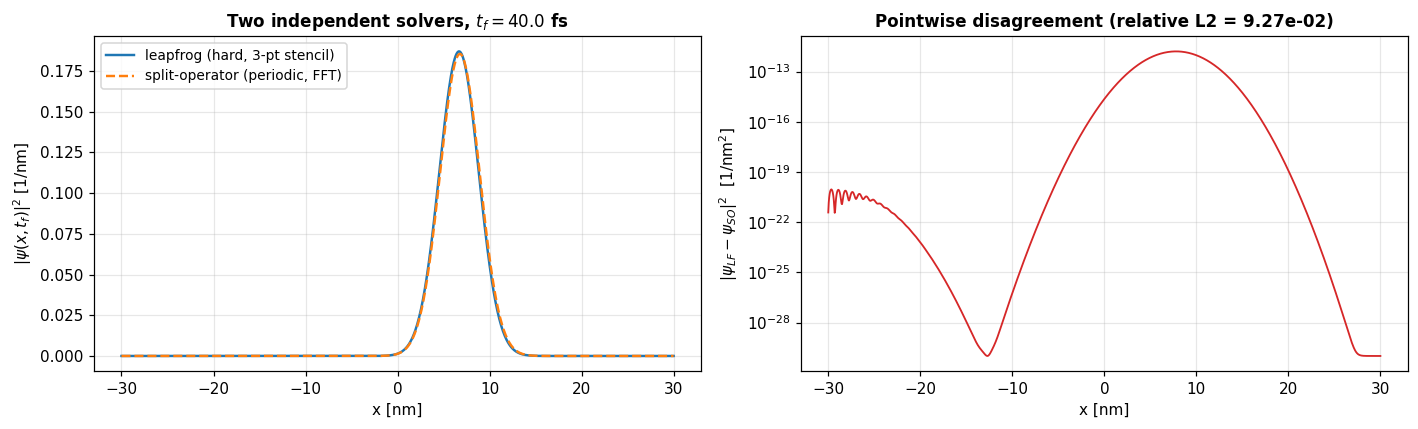

In [10]:
g  = gridmod.make_grid_nm(-30, 30, 1201)
sigma0 = 1.5*units.NM
psi0 = gridmod.gaussian_packet(g, x0=-10*units.NM, sigma=sigma0,
                                k0=units.wavenumber_from_energy(0.5*units.EV))
V    = potentials.free(g)
dt   = gridmod.visscher_dt_max(g, V_max=0.0, safety=0.5)
n_steps = int(40*units.FS / dt)

lf = solvers.LeapfrogSolver(g, V, dt=dt, bc="hard")
so = solvers.SplitOperatorSolver(g, V, dt=dt, bc="periodic")
r_lf = lf.run(psi0, n_steps=n_steps, n_save=2, track_energy=False)
r_so = so.run(psi0, n_steps=n_steps, n_save=2, track_energy=False)

psi_lf, psi_so = r_lf.psi[-1], r_so.psi[-1]
err = np.linalg.norm(psi_lf - psi_so) / np.linalg.norm(psi_so)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.0))
ax[0].plot(g.x/units.NM, np.abs(psi_lf)**2 * units.NM, lw=1.6,
           label="leapfrog (hard, 3-pt stencil)")
ax[0].plot(g.x/units.NM, np.abs(psi_so)**2 * units.NM, ls="--", lw=1.6,
           label="split-operator (periodic, FFT)")
ax[0].set_xlabel("x [nm]"); ax[0].set_ylabel(r"$|\psi(x, t_f)|^2$ [1/nm]")
ax[0].set_title(f"Two independent solvers, $t_f = {n_steps*dt/units.FS:.1f}$ fs")
ax[0].legend(fontsize=9)
ax[1].semilogy(g.x/units.NM,
               np.abs(psi_lf - psi_so)**2 * units.NM**2 + 1e-30,
               lw=1.2, color="C3")
ax[1].set_xlabel("x [nm]")
ax[1].set_ylabel(r"$|\psi_{LF} - \psi_{SO}|^2$  [1/nm$^2$]")
ax[1].set_title(rf"Pointwise disagreement (relative L2 = {err:.2e})")
fig.tight_layout(); plt.show()

The two density curves overlay to graphical precision; the pointwise
$|\psi_{LF} - \psi_{SO}|^2$ stays many decades below the peak density,
and the relative L2 disagreement is bounded by the sum of the
independent O$(\Delta t^2)$ and O$(\Delta x^2)$ error coefficients of
the two schemes.  This four-way validation (analytic + Crank–Nicolson
+ transfer-matrix + FFT split-operator) is what makes the project's
conservation diagnostics trustworthy.

## Summary of breaking-point experiments

| failure                  | onset                            | mitigation                             |
|--------------------------|----------------------------------|----------------------------------------|
| CFL violation            | $\Delta t > \Delta t_c$          | safety factor $\le 0.9$                |
| Ordinary-norm wobble     | always (it's $O(\Delta t^2)$)    | use Visscher norm as monitor           |
| Numerical dispersion     | $k_{\max}\Delta x \gtrsim 0.35$ | refine $\Delta x$ or smooth high-k components  |
| Aliased tunnelling tail  | $\kappa\,\Delta x \gtrsim 0.3$  | refine $\Delta x$ in barrier region    |
| Energy oscillation       | always (symplectic)              | bounded — accept it                    |
| Hard-wall recurrences    | packet reaches the wall          | absorbing boundaries                   |
| Stiff-potential ripples  | discontinuous $V$                | smooth over 2-3 grid cells             |
| Hidden stencil bug       | shared spatial discretisation    | cross-check with FFT split-operator    |

These eight observations form the heart of the project's
*numerical analysis* discussion.